# Práctica 3 · Parte 1 — Autoencoder convolucional
**Aprendizaje Profundo · Grado en Inteligencia Artificial · Universidade da Coruña · Curso 2026/2027**

**Integrantes:** _Sneshanca Blanca Andrés Ochoa_, _Pedro José Agrelo Márquez_

---

### Contexto: ¿qué es la práctica 3?
La práctica completa construye un **simulador neuronal ("world model") de CarRacing**. Recibe las 12 imágenes más recientes del juego y 35 acciones discretas (11 pasadas y 24 futuras) y genera las **24 imágenes siguientes**, unos 1,92 s de juego. No se aprende a conducir ni se usa aprendizaje por refuerzo: solo se aprende a **predecir lo que se verá en pantalla**.

El sistema final tiene tres piezas:
1. **Encoder** `E`: comprime cada imagen `x_t` (48×48×3) en un vector latente `z_t ∈ R^d`.
2. **Predictor temporal** (LSTM en la parte 3, transformer en la parte 4): a partir de los latentes y las acciones, predice el latente siguiente `ẑ_{t+1}`.
3. **Decoder** `D`: convierte el latente predicho en imagen, `x̂_{t+1} = D(ẑ_{t+1})`.

Predecir en el espacio latente (un vector de `d` números) es mucho más barato y estable que predecir directamente 6912 píxeles. Por eso primero se necesita un buen autoencoder.

### Objetivo de esta parte (parte 1)
Construir y entrenar el **autoencoder**, que es la base de todo lo demás:
- **Entrada y objetivo:** un único fotograma `x_t` de forma (48, 48, 3), normalizado a [0, 1]. **No** se usan acciones, **no** se usan secuencias de 12 imágenes y **no** se predice `x_{t+1}`.
- **Esquema:** `x_t → encoder → z_t ∈ R^d → decoder → x̃_t`, con pérdida `L = MSE(x_t, x̃_t)`.
- **Experimento:** comparar **dos tamaños del espacio latente** (d = 32 y d = 128) manteniendo constante todo lo demás.
- **Además:** generar y guardar los datos con las particiones por circuito (se reutilizan en toda la práctica) y crear la **referencia sin entrenamiento** de repetir la última imagen, que servirá para comparar los predictores de las partes siguientes.

### Índice
0. Configuración del entorno (Drive, dependencias, librerías)
1. Generación y guardado de datos por circuito
2. Inspección de una secuencia (imágenes, acciones, alineación) y del entorno
3. Referencia sin entrenamiento: repetir la última imagen 24 pasos
4. Preparación de los datos para el autoencoder
5. Arquitectura del autoencoder convolucional (sin conexiones residuales)
6. Entrenamiento y comparación de dos tamaños latentes
7. Reconstrucciones, mapas de error y comprobación de los modelos guardados
8. Conclusiones
9. Guía para la defensa
10. Declaración de ayuda externa e IA

## 0. Configuración del entorno

1. Detecta si estamos en Colab (si se ejecuta en local, la celda no hace nada especial y usa el directorio actual).
2. Monta Drive en `/content/drive`.
3. Cambia el directorio de trabajo a la carpeta del proyecto (`os.chdir`). Todos los ficheros que se guardan después (`datos/`, `modelos/`, `resultados/`) quedan en Drive y se conservan entre sesiones y entre semanas.
4. Si en la carpeta está  `ficheros_ayuda.zip`, lo descomprime.
5. Añade la carpeta a `sys.path` para que Python encuentre los módulos de (`dataset.py`, `carracing48.py`, `metric.py`) al hacer `import`.
6. Comprueba que esos ficheros existen y, si falta alguno, se detiene con un error claro.


In [1]:
import os, sys

# Ruta de la carpeta del proyecto en Google Drive
PROJECT_DIR = "/content/drive/MyDrive/AP/P3"

# Detectamos si estamos en Colab: el módulo google.colab solo existe allí
try:
    from google.colab import drive
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    drive.mount("/content/drive")             # pide permiso la primera vez y monta Drive
    os.makedirs(PROJECT_DIR, exist_ok=True)   # crea la carpeta si no existe
    os.chdir(PROJECT_DIR)                     # a partir de aquí, las rutas relativas apuntan a Drive
    # Si el zip de ayuda está en la carpeta pero no se ha descomprimido, lo descomprime
    if not os.path.exists("dataset.py") and os.path.exists("ficheros_ayuda.zip"):
        import zipfile
        zipfile.ZipFile("ficheros_ayuda.zip").extractall(".")

# Añadimos la carpeta actual a la ruta de búsqueda de módulos para poder hacer "import dataset", etc.
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())

print("Directorio de trabajo:", os.getcwd())

# Comprobación: sin estos ficheros del profesor el notebook no puede funcionar
needed = ["dataset.py", "carracing48.py", "metric.py", "requirements.txt"]
missing = [f for f in needed if not os.path.exists(f)]
assert not missing, f"Faltan ficheros en la carpeta: {missing}"
print("Ficheros encontrados")

Mounted at /content/drive
Directorio de trabajo: /content/drive/MyDrive/AP/P3
Ficheros encontrados


### 0.2 Instalación de dependencias
- `gymnasium[box2d]` incluye el entorno CarRacing, el motor de física **Box2D** y **Pygame** para dibujar las imágenes.
- `scikit-image` se usa en `metric.py` para calcular el **SSIM**.
- `pandas` se usa para la tabla de resultados y para el formato CSV de Kaggle.

El paquete `box2d-py` a veces no tiene versión precompilada y hay que compilarlo, para lo que necesita la herramienta **SWIG**. Por eso se instala `swig` primero. Colab no conserva lo instalado entre sesiones, así que esta celda hay que ejecutarla **cada vez que se abre el notebook**. Keras y TensorFlow ya vienen instalados en Colab.

In [2]:
# Box2D a veces necesita compilarse: instalar swig antes evita el error de compilación
%pip install -q swig
# Dependencias indicadas por el profesor: gymnasium[box2d], scikit-image y pandas
%pip install -q -r requirements.txt

### 0.3 Librerías, semilla y carpetas
- **Variables `SDL_*` = `"dummy"`:** Pygame (que usa el entorno para dibujar) intenta abrir una ventana y un dispositivo de audio. En Colab no hay pantalla, así que se le indica que use controladores "vacíos".
- **`KERAS_BACKEND = "tensorflow"`:** Keras 3 puede funcionar sobre TensorFlow, JAX o PyTorch; fijamos TensorFlow.
- **Semilla global (`SEED = 42`):** `keras.utils.set_random_seed` fija a la vez las semillas de Python, NumPy y TensorFlow. Así la inicialización de pesos y el barajado de los datos son repetibles.
- **Carpetas:** `datos/` (secuencias y metadatos), `modelos/` (ficheros `.keras`) y `resultados/` (métricas y tablas).
- **Acciones:** son **enteros**, no magnitudes continuas: 0 = nada, 1 = derecha, 2 = izquierda, 3 = acelerar, 4 = frenar. No hay acciones simultáneas.


In [3]:
import os
# Pygame (usado por el entorno para dibujar) no tiene pantalla ni audio en Colab: usamos controladores vacíos
os.environ.setdefault("SDL_VIDEODRIVER", "dummy")
os.environ.setdefault("SDL_AUDIODRIVER", "dummy")
# Keras 3 admite varios backends; usamos TensorFlow
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import json, time, platform
import numpy as np
import matplotlib.pyplot as plt
import keras
from keras import layers

# Módulos
from dataset import generate_sequences, CONTEXT_LENGTH, PREDICTION_LENGTH  # CONTEXT_LENGTH=12, PREDICTION_LENGTH=24
from carracing48 import make_env                                            # entorno de 48x48 para explorarlo
from metric import visual_metrics                                           # score, SSIM, gradiente y MSE

SEED = 42
keras.utils.set_random_seed(SEED)   # fija Python, NumPy y backend: inicialización y barajado reproducibles

# Carpetas de trabajo
DATA_DIR, MODEL_DIR, RESULTS_DIR = "datos", "modelos", "resultados"
for d in (DATA_DIR, MODEL_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

# Significado de cada acción entera (solo para mostrarlas; el autoencoder no las usa)
ACTION_NAMES = {0: "nada", 1: "derecha", 2: "izquierda", 3: "acelerar", 4: "frenar"}

# Documentamos el entorno de ejecución
import tensorflow as tf
print("Python", platform.python_version(), "| Keras", keras.__version__,
      "| backend", keras.backend.backend(), "| TF", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "no disponible")

Python 3.13.16 | Keras 3.13.2 | backend tensorflow | TF 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Generación de datos con semillas distintas

### Cómo se generan los datos
`generate_sequences(seed, n_sequences)` (de `dataset.py`):
- Crea un **circuito aleatorio** distinto para cada secuencia (la forma de la pista se obtiene a partir de la semilla).
- Conduce el coche con una **política automática**: sigue la pista mirando un punto 5 tramos por delante y gira si el ángulo es grande. Un 25 % de las veces elige una acción al azar, con probabilidades 10 % nada, 15 % derecha, 15 % izquierda, 50 % acelerar y 10 % frenar, para que haya variedad. Esta política solo sirve para recoger datos; nunca es entrada del modelo.
- Antes de empezar a grabar ejecuta entre **0 y 200 pasos de calentamiento** (número aleatorio). Así las secuencias no empiezan siempre con el coche parado en la salida.
- Graba **96 fotogramas consecutivos** y **95 acciones** por circuito. Cada paso repite la acción durante 4 pasos de física, lo que equivale a 0,08 s simulados.
- Devuelve `frames` con forma (N, 96, 48, 48, 3) en `uint8` (0–255) y `actions` con forma (N, 95) en enteros 0–4.

### Por qué semillas distintas para entrenamiento y validación
- **Entrenamiento:** semilla 1234, 128 circuitos → 128 × 96 = 12 288 fotogramas.
- **Validación:** semilla 5678, 32 circuitos → 32 × 96 = 3072 fotogramas.

Con semillas distintas, los circuitos de validación son **distintos** de los de entrenamiento. Así evitamos que fotogramas de un mismo circuito estén en entrenamiento y validación.

Los datos de Kaggle (`test_inputs.npz`) **no** se usan ni para entrenar ni para elegir hiperparámetros.

### Por qué se guardan en disco
- La generación es **lenta** (unos 20 minutos en total) porque el simulador de física corre en CPU fotograma a fotograma; la GPU no ayuda.
- `dataset.py` solo garantiza la reproducibilidad con la **misma semilla, las mismas versiones y la misma plataforma**. Si Colab actualiza una librería, la misma semilla podría dar otros datos. Por eso se guardan los **arrays**, no solo las semillas.
- Estas particiones se **reutilizan en todas las partes** de la práctica.

La función `load_or_generate` comprueba si el fichero ya existe: si existe lo carga; si no, lo genera, lo guarda comprimido (`.npz`) y guarda también un `_meta.json` con la semilla, el tiempo de generación, la versión de Python y la semilla de cada circuito.

In [ ]:
# Semillas y tamaños de cada partición (semillas distintas → circuitos distintos)
TRAIN_SEED, VALID_SEED = 1234, 5678
N_TRAIN, N_VALID = 128, 32

def load_or_generate(name, seed, n):
    """Carga datos/<name>.npz si existe; si no, los genera con generate_sequences y los guarda."""
    path = os.path.join(DATA_DIR, f"{name}.npz")
    meta_path = os.path.join(DATA_DIR, f"{name}_meta.json")
    if os.path.exists(path):
        data = np.load(path)
        print(f"{name}: cargado de {path}")
        return {"frames": data["frames"], "actions": data["actions"]}
    t0 = time.time()
    # Callback que muestra el progreso cada 8 secuencias
    def progress(done, total):
        if done % 8 == 0 or done == total:
            print(f"  {name}: {done}/{total} secuencias ({time.time()-t0:.0f}s)", flush=True)
    # return_metadata=True devuelve además la semilla de cada circuito y los pasos de calentamiento
    data, meta = generate_sequences(seed=seed, n_sequences=n,
                                    return_metadata=True, progress=progress)
    np.savez_compressed(path, **data)   # guarda frames y actions comprimidos
    # Metadatos para reproducibilidad: semilla, tiempo, versión de Python y circuitos usados
    with open(meta_path, "w") as f:
        json.dump({"seed": seed, "n_sequences": n, "generation_seconds": time.time()-t0,
                   "python": platform.python_version(), "circuits": meta}, f, indent=1)
    print(f"{name}: generado en {time.time()-t0:.0f}s y guardado en {path}")
    return data

train = load_or_generate("train", TRAIN_SEED, N_TRAIN)
valid = load_or_generate("valid", VALID_SEED, N_VALID)

# Formas esperadas: frames (N, 96, 48, 48, 3) uint8 y actions (N, 95) enteros
for name, d in [("train", train), ("valid", valid)]:
    print(f"{name}: frames {d['frames'].shape} {d['frames'].dtype} | actions {d['actions'].shape} {d['actions'].dtype}")

train: cargado de datos/train.npz
valid: cargado de datos/valid.npz
train: frames (128, 96, 48, 48, 3) uint8 | actions (128, 95) int64
valid: frames (32, 96, 48, 48, 3) uint8 | actions (32, 95) int64


### Comprobaciones de los datos
Antes de usar los datos se verifica:
- Las imágenes tienen forma (N, T, 48, 48, 3) y tipo `uint8`.
- Hay exactamente **T − 1 acciones** por secuencia (95 para 96 fotogramas), porque cada acción une dos fotogramas consecutivos.
- Las acciones están entre 0 y 4.
- **No hay ningún circuito compartido** entre entrenamiento y validación, comparando la semilla de cada circuito guardada en los metadatos.

Resultado: 0 circuitos compartidos.

In [ ]:
# Comprobaciones básicas de formato
for name, d in [("train", train), ("valid", valid)]:
    f, a = d["frames"], d["actions"]
    assert f.ndim == 5 and f.shape[2:] == (48, 48, 3) and f.dtype == np.uint8   # (N, T, 48, 48, 3) en uint8
    assert a.shape == (f.shape[0], f.shape[1] - 1), "Debe haber T-1 acciones por secuencia"
    assert a.min() >= 0 and a.max() <= 4                                         # acciones válidas 0..4

# Conjunto de semillas de circuito de una partición (guardadas en los metadatos)
def circuits(name):
    with open(os.path.join(DATA_DIR, f"{name}_meta.json")) as fh:
        return {c["track_seed"] for c in json.load(fh)["circuits"]}

# Ningún circuito puede estar a la vez en entrenamiento y validación (evita fugas de información)
if os.path.exists(os.path.join(DATA_DIR, "train_meta.json")):
    shared = circuits("train") & circuits("valid")
    print("Circuitos compartidos entre train y valid:", len(shared))
    assert not shared
print("Formatos correctos ✔")

Circuitos compartidos entre train y valid: 0
Formatos correctos ✔


## 2. Inspección de una secuencia
Vamos a inspeccionar una secuencia para conocer los datos: imágenes, acciones y **alineación temporal**.

**Regla de alineación:** `actions[i, j]` es la acción que lleva de `frames[i, j]` a `frames[i, j+1]`. Es decir, la acción `a_t` se aplica estando en `x_t` y produce `x_{t+1}`.

Las acciones **solo se inspeccionan**; **no** se le dan al autoencoder.

### Qué se ve en cada imagen
- **Pista gris** y **hierba verde** (con cuadrados de un verde más claro como textura).
- **Bordillos rojos y blancos** en las curvas.
- **Coche rojo** siempre en la misma posición, abajo en el centro: la cámara sigue al coche y gira con él, así que es el mundo el que se mueve.
- **Barra negra inferior de indicadores** (HUD): a la izquierda la puntuación y la velocidad (blanco); en azul los sensores ABS de las cuatro ruedas; en **verde** la dirección de las ruedas (giro); en **rojo** el giroscopio (velocidad de giro del coche). Son muy pocos píxeles, pero contienen información sobre el **estado del coche** que no se deduce bien del resto de la imagen.

La primera figura muestra 12 fotogramas consecutivos (los 12 que formarían un contexto) con la acción aplicada en cada uno.

Fotogramas: (96, 48, 48, 3) | acciones: (95,)
Primeras 20 acciones: ['derecha', 'acelerar', 'izquierda', 'acelerar', 'izquierda', 'acelerar', 'izquierda', 'acelerar', 'izquierda', 'izquierda', 'izquierda', 'acelerar', 'derecha', 'izquierda', 'izquierda', 'acelerar', 'izquierda', 'acelerar', 'frenar', 'acelerar']


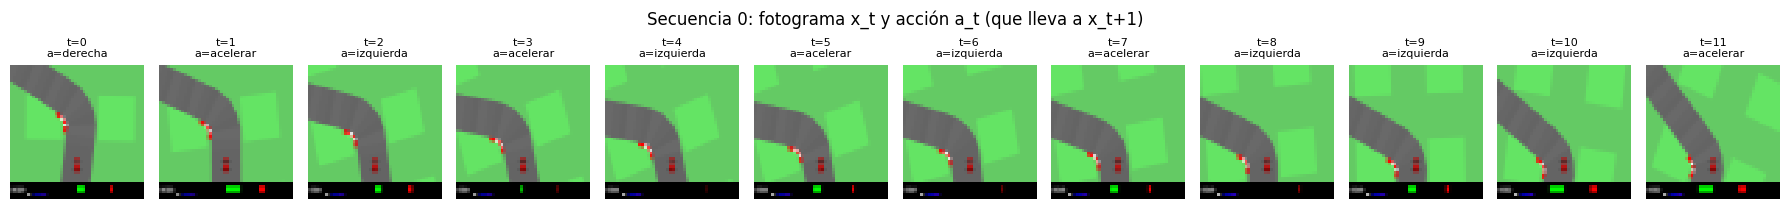

In [ ]:
i = 0                                                      # secuencia (circuito) que inspeccionamos
frames_i, actions_i = train["frames"][i], train["actions"][i]
print("Fotogramas:", frames_i.shape, "| acciones:", actions_i.shape)   # (96, 48, 48, 3) y (95,)
print("Primeras 20 acciones:", [ACTION_NAMES[a] for a in actions_i[:20]])

# Tira de 12 fotogramas consecutivos con la acción que se aplica en cada uno
fig, axes = plt.subplots(1, 12, figsize=(18, 2.2))
for j, ax in enumerate(axes):
    ax.imshow(frames_i[j], interpolation="nearest")       # "nearest" para ver los píxeles reales, sin suavizar
    ax.set_title(f"t={j}\na={ACTION_NAMES[actions_i[j]]}", fontsize=8)
    ax.axis("off")
plt.suptitle(f"Secuencia {i}: fotograma x_t y acción a_t (que lleva a x_t+1)")
plt.tight_layout(); plt.show()

### Comprobación visual de la alineación y distribución de acciones
Para cada tipo de acción se busca la primera vez que aparece en la secuencia y se muestran:
- `x_j` (antes de la acción), `x_{j+1}` (después de la acción `a_j`) y
- el **mapa de diferencias** `|x_{j+1} − x_j|`, que indica qué ha cambiado entre los dos fotogramas.

Al acelerar, la pista se desplaza hacia abajo (el coche avanza). Al girar, la escena rota alrededor del coche y cambia el indicador verde de dirección. Esto confirma que la acción `a_j` explica el cambio de `x_j` a `x_{j+1}`.

Después se muestra la **distribución de acciones** en entrenamiento. Domina **acelerar** (≈ 50 %), seguida de **izquierda** (≈ 25 %) y **derecha** (≈ 20 %); **nada** y **frenar** son muy poco frecuentes (≈ 2 % cada una). Es coherente con la política de recogida, que acelera por defecto y gira para seguir la pista. Esto será relevante en las partes 3–5: el predictor verá pocos ejemplos de frenar o no hacer nada, así que probablemente predecirá peor esas situaciones.

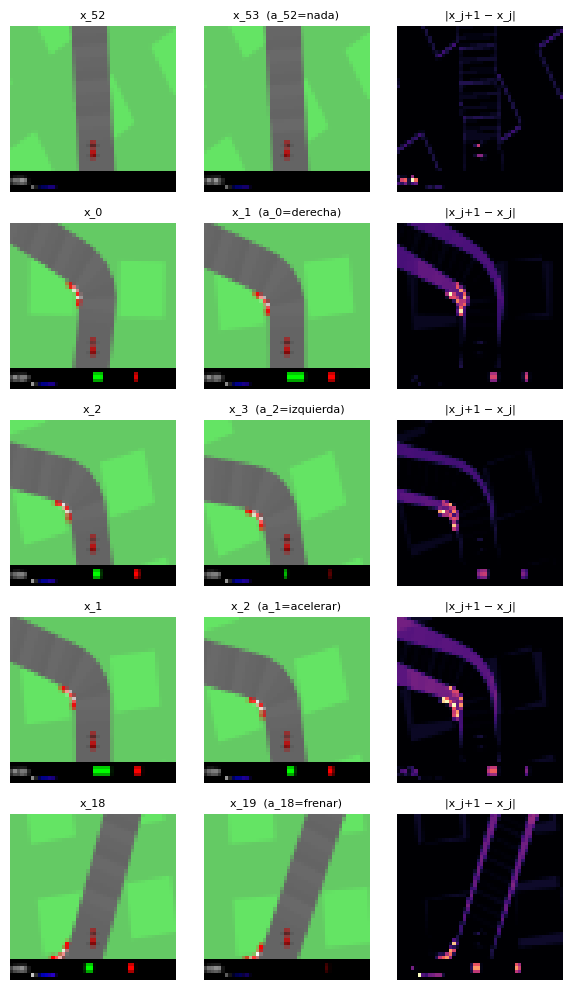

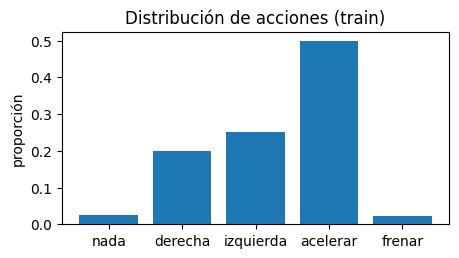

In [ ]:
# Alineación: para cada acción, su primera aparición j → x_j, x_{j+1} y la diferencia entre ambos
js = [int(np.where(actions_i == a)[0][0]) for a in range(5) if (actions_i == a).any()]
fig, axes = plt.subplots(len(js), 3, figsize=(6, 2 * len(js)))
for row, j in zip(np.atleast_2d(axes), js):
    # Diferencia absoluta media por píxel (se pasa a int para que no haya desbordamiento con uint8)
    diff = np.abs(frames_i[j + 1].astype(int) - frames_i[j].astype(int)).mean(-1)
    row[0].imshow(frames_i[j], interpolation="nearest"); row[0].set_title(f"x_{j}", fontsize=8)
    row[1].imshow(frames_i[j + 1], interpolation="nearest"); row[1].set_title(f"x_{j+1}  (a_{j}={ACTION_NAMES[actions_i[j]]})", fontsize=8)
    row[2].imshow(diff, cmap="magma"); row[2].set_title("|x_j+1 − x_j|", fontsize=8)
    for ax in row: ax.axis("off")
plt.tight_layout(); plt.show()

# Distribución de acciones en entrenamiento (proporción de cada acción sobre el total)
counts = np.bincount(train["actions"].ravel(), minlength=5)
plt.figure(figsize=(5, 2.5))
plt.bar([ACTION_NAMES[k] for k in range(5)], counts / counts.sum())
plt.title("Distribución de acciones (train)"); plt.ylabel("proporción"); plt.show()

### Exploración del entorno con `make_env`
Vamos a usar `make_env()` de `carracing48.py` y sus métodos `reset`, `step` y `render` para explorar el juego:
- `env.reset(seed)` crea un circuito nuevo y devuelve la primera observación.
- `env.step(a)` aplica la acción entera `a` (internamente la repite 4 pasos de física) y devuelve la nueva observación, la recompensa y si el episodio ha terminado.
- `env.render()` devuelve la imagen actual de 48×48×3; se comprueba que coincide con la observación devuelta por `step`.

Se aplican 10 pasos acelerando, 5 girando a la izquierda y 5 a la derecha, y se muestra un fotograma cada 3 pasos. Es solo exploración: estas imágenes no se usan para entrenar.

Observación: (48, 48, 3) uint8


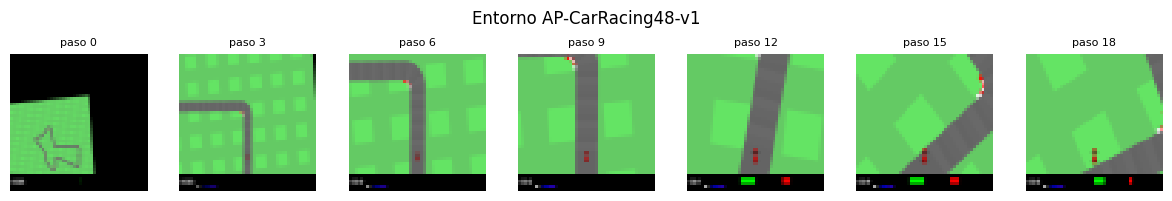

In [ ]:
# Exploración rápida del entorno con make_env (reset, step, render)
env = make_env(seed=0)
obs, _ = env.reset(seed=0)                 # nuevo circuito (semilla 0) y primera observación
seq_env = [obs]
for a in [3] * 10 + [2] * 5 + [1] * 5:     # acelerar, girar izquierda, girar derecha
    obs, reward, term, trunc, _ = env.step(a)
    seq_env.append(obs)
assert np.array_equal(env.render(), obs)   # render() devuelve la misma imagen que la última observación
env.close()
print("Observación:", obs.shape, obs.dtype)   # (48, 48, 3) uint8

# Un fotograma cada 3 pasos
fig, axes = plt.subplots(1, 7, figsize=(12, 2))
for ax, j in zip(axes, range(0, 21, 3)):
    ax.imshow(seq_env[j], interpolation="nearest"); ax.set_title(f"paso {j}", fontsize=8); ax.axis("off")
plt.suptitle("Entorno AP-CarRacing48-v1"); plt.tight_layout(); plt.show()

## 3. Referencia sin entrenamiento: repetir la última imagen

### Qué es y para qué sirve
Es el predictor más sencillo posible: **no aprende nada**. Toma el último fotograma observado `x_t` y lo devuelve como predicción de los 24 siguientes:

$$\hat{x}_{t+1} = \hat{x}_{t+2} = \dots = \hat{x}_{t+24} = x_t$$

Sirve como **línea base**: un predictor de las partes 3–5 que no mejore esta referencia no está aportando nada. También es lo que hace `sample_submission.csv` de Kaggle. Se crea  **por separado y sin entrenamiento**, sin relación con el autoencoder.

### Ventanas de evaluación
Para evaluarla hay que construir ventanas a partir de las secuencias largas. Una ventana que empieza en `s` contiene:
- **Contexto:** `x_s, …, x_{s+11}` (12 imágenes observadas).
- **Objetivos:** `x_{s+12}, …, x_{s+35}` (24 imágenes a predecir).
- **Acciones:** `a_s, …, a_{s+34}` (35 acciones: 11 históricas que unen las imágenes del contexto + 24 futuras, que empiezan en `a_{s+11}`).

Cada ventana ocupa 36 fotogramas, así que con T = 96 y paso 1 hay **T − 35 = 61 ventanas** por circuito. Las ventanas nunca cruzan de un circuito a otro.

Aquí se usa **paso 12** (una ventana cada 12 fotogramas: s = 0, 12, 24, 36, 48, 60) sobre los 32 circuitos de validación → 6 × 32 = **192 ventanas**. Con paso 1 las ventanas se solaparían mucho y el cálculo sería 12 veces más lento sin aportar información nueva.

Se comprueba la alineación: el último fotograma del contexto es `frames[11]` y el primer objetivo es `frames[12]`.

### Métricas (`visual_metrics` de `metric.py`)
Todas reciben imágenes en [0, 1]; **menor es mejor** salvo el SSIM:
- **MSE:** error cuadrático medio por píxel. Es sencillo, pero no refleja bien la percepción humana: una imagen borrosa puede tener buen MSE.
- **SSIM** (similitud estructural, entre −1 y 1, 1 = idéntica): compara luminancia, contraste y estructura en ventanas de 7×7 píxeles. Se parece más a la percepción humana.
- **Gradiente (G):** compara las diferencias entre píxeles vecinos (bordes) de la imagen real y la predicha. Penaliza las imágenes borrosas.
- **Score** (la métrica de Kaggle): `0,8 · (1 − SSIM)/2 + 0,2 · G`. Vale 0 si la predicción es exacta.

Se calcula la métrica global y la métrica **por horizonte** `h = 1…24` (cómo de bien se predice el fotograma que está `h` pasos en el futuro). Los resultados se guardan en `resultados/baseline_repeat_last.npz` para compararlos en las partes siguientes.

**Resultado:** score global 0,101, SSIM 0,751 y MSE 0,0156. El error crece muy rápido en los primeros pasos (score ≈ 0,060 en h = 1) y se estabiliza en torno a 0,10–0,107 a partir de h ≈ 5–6. A partir de ahí la imagen repetida ya no se parece a la real (el coche ha avanzado y la pista ha cambiado), y el error deja de crecer porque ya es "máximo" para este método.

Ventanas válidas por circuito con paso 1: 61
Ventanas de evaluación: (192, 12, 48, 48, 3) (192, 24, 48, 48, 3) (192, 35)
Repetir la última imagen (24 pasos): {'score': 0.101, 'ssim': 0.7511, 'gradient': 0.0071, 'mse': 0.0156}


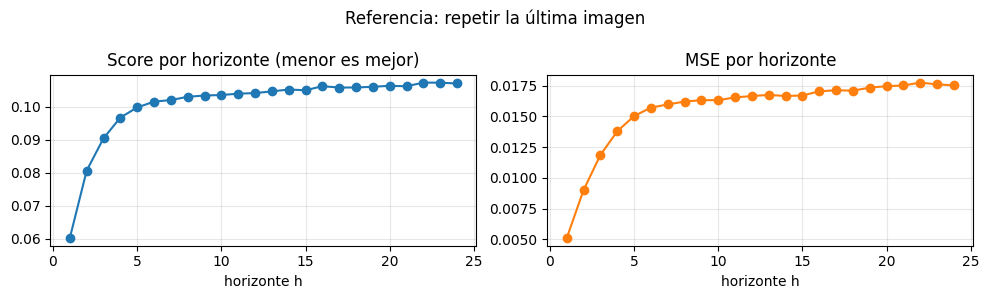

In [ ]:
def make_windows(frames, actions, stride=1):
    """Corta las secuencias largas en ventanas de 12 imágenes de contexto + 24 objetivos.

    frames (N,T,48,48,3), actions (N,T-1) -> context (W,12,...), targets (W,24,...), actions (W,35)
    """
    T = frames.shape[1]
    # Inicios válidos: la ventana ocupa 36 fotogramas, así que s va de 0 a T-36 → T-35 ventanas con paso 1
    starts = range(0, T - (CONTEXT_LENGTH + PREDICTION_LENGTH) + 1, stride)
    ctx, tgt, act = [], [], []
    for n in range(frames.shape[0]):             # cada secuencia = un circuito, sin mezclar
        for s in starts:
            ctx.append(frames[n, s:s + CONTEXT_LENGTH])                                        # x_s .. x_{s+11}
            tgt.append(frames[n, s + CONTEXT_LENGTH:s + CONTEXT_LENGTH + PREDICTION_LENGTH])   # x_{s+12} .. x_{s+35}
            act.append(actions[n, s:s + CONTEXT_LENGTH + PREDICTION_LENGTH - 1])               # a_s .. a_{s+34} (35)
    return np.stack(ctx), np.stack(tgt), np.stack(act)

def repeat_last_baseline(context):
    """Referencia sin entrenamiento: repite el último fotograma del contexto 24 veces.

    context (B,12,48,48,3) -> (B,24,48,48,3)
    """
    return np.repeat(context[:, -1:], PREDICTION_LENGTH, axis=1)   # context[:, -1:] mantiene el eje temporal

T = valid["frames"].shape[1]
print("Ventanas válidas por circuito con paso 1:", T - 35)   # 61 con T = 96

# Ventanas de validación con paso 12 (6 por circuito × 32 circuitos = 192)
ctx_v, tgt_v, act_v = make_windows(valid["frames"], valid["actions"], stride=12)
# Comprobación de alineación: el primer objetivo es el fotograma siguiente al último del contexto
assert np.array_equal(tgt_v[0, 0], valid["frames"][0, 12]) and np.array_equal(ctx_v[0, -1], valid["frames"][0, 11])
print("Ventanas de evaluación:", ctx_v.shape, tgt_v.shape, act_v.shape)

# Predicción de la referencia y normalización a [0, 1] (las métricas lo exigen)
pred_v = repeat_last_baseline(ctx_v)
Y, P = tgt_v.astype("float32") / 255, pred_v.astype("float32") / 255
baseline_global = visual_metrics(Y, P)                                             # sobre los 24 horizontes
baseline_by_h = [visual_metrics(Y[:, h], P[:, h]) for h in range(PREDICTION_LENGTH)]  # un valor por horizonte
print("Repetir la última imagen (24 pasos):", {k: round(v, 4) for k, v in baseline_global.items()})

# Guardamos las métricas por horizonte para comparar con los predictores de las partes 3-5
np.savez_compressed(os.path.join(RESULTS_DIR, "baseline_repeat_last.npz"),
                    score=[m["score"] for m in baseline_by_h], ssim=[m["ssim"] for m in baseline_by_h],
                    mse=[m["mse"] for m in baseline_by_h], window_stride=12)

# Curvas de error por horizonte
hs = np.arange(1, PREDICTION_LENGTH + 1)
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
ax[0].plot(hs, [m["score"] for m in baseline_by_h], marker="o"); ax[0].set_title("Score por horizonte (menor es mejor)")
ax[1].plot(hs, [m["mse"] for m in baseline_by_h], marker="o", color="C1"); ax[1].set_title("MSE por horizonte")
for a in ax: a.set_xlabel("horizonte h"); a.grid(alpha=.3)
plt.suptitle("Referencia: repetir la última imagen"); plt.tight_layout(); plt.show()

### Ejemplo visual de la referencia
Para una ventana se muestran, en varios horizontes (h = 1, 4, 8, 12, 18, 24):
- **Fila 1:** la imagen real futura.
- **Fila 2:** la predicción de la referencia (siempre la misma imagen, el último fotograma del contexto).
- **Fila 3:** el mapa de error absoluto medio por píxel (más claro = más error).

El error crece con el horizonte, porque la pista real se va alejando de la imagen congelada.

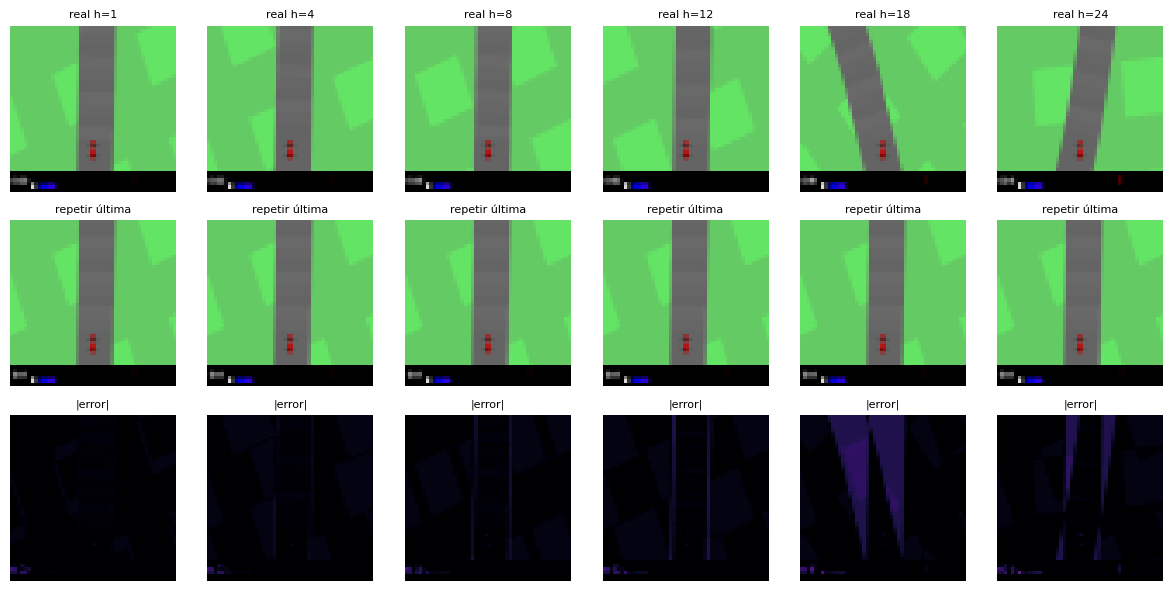

In [ ]:
# Ejemplo visual de la referencia: realidad, predicción y error en algunos horizontes
w, show_h = 0, [0, 3, 7, 11, 17, 23]          # ventana 0; índices 0..23 corresponden a h = 1..24
fig, axes = plt.subplots(3, len(show_h), figsize=(12, 6))
for c, h in enumerate(show_h):
    axes[0, c].imshow(Y[w, h], interpolation="nearest"); axes[0, c].set_title(f"real h={h+1}", fontsize=8)
    axes[1, c].imshow(P[w, h], interpolation="nearest"); axes[1, c].set_title("repetir última", fontsize=8)
    # Error absoluto medio sobre los 3 canales; escala fija 0..1 para comparar entre horizontes
    axes[2, c].imshow(np.abs(Y[w, h] - P[w, h]).mean(-1), cmap="magma", vmin=0, vmax=1); axes[2, c].set_title("|error|", fontsize=8)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 4. Datos para el autoencoder
El autoencoder trabaja con **fotogramas individuales**, no con secuencias, así que se "aplanan" las dos primeras dimensiones:
- `train["frames"]`: (128, 96, 48, 48, 3) → `X_train`: (128 × 96, 48, 48, 3) = (**12 288**, 48, 48, 3).
- `valid["frames"]`: (32, 96, 48, 48, 3) → `X_val`: (**3072**, 48, 48, 3).

Los píxeles se pasan de enteros 0–255 a reales en [0, 1] dividiendo entre 255. Así la salida sigmoide del decoder (que también da valores en [0, 1]) se puede comparar directamente con la entrada, y los valores pequeños favorecen un entrenamiento estable.

**Imágenes de evaluación fijas:** se eligen 512 imágenes de validación al azar (con semilla fija) y se guardan sus índices y las imágenes en `datos/eval_images.npz`.

In [ ]:
# Fotogramas individuales: (N, T, 48, 48, 3) -> (N*T, 48, 48, 3), normalizados a [0, 1]
X_train = train["frames"].reshape(-1, 48, 48, 3).astype("float32") / 255.0
X_val = valid["frames"].reshape(-1, 48, 48, 3).astype("float32") / 255.0
print("X_train:", X_train.shape, f"[{X_train.min():.2f}, {X_train.max():.2f}]")
print("X_val:  ", X_val.shape)

# Imágenes fijas de evaluación (se reutilizan en la parte 2 para comparar sobre las mismas imágenes)
eval_path = os.path.join(DATA_DIR, "eval_images.npz")
if os.path.exists(eval_path):
    eval_idx = np.load(eval_path)["indices"]          # si ya existen, se reutilizan los mismos índices
else:
    # 512 índices de validación sin repetición, con semilla fija para que sean siempre los mismos
    eval_idx = np.sort(np.random.default_rng(SEED).choice(len(X_val), size=512, replace=False))
    np.savez_compressed(eval_path, indices=eval_idx, images=valid["frames"].reshape(-1, 48, 48, 3)[eval_idx])
X_eval = X_val[eval_idx]
print("Imágenes de evaluación fijas:", X_eval.shape)

X_train: (12288, 48, 48, 3) [0.00, 0.99]
X_val:   (3072, 48, 48, 3)
Imágenes de evaluación fijas: (512, 48, 48, 3)


## 5. Autoencoder convolucional (sin conexiones residuales)

### Idea
Un autoencoder aprende a **comprimir** una imagen en un vector pequeño (el **latente** `z`) y a **reconstruirla** a partir de él. Como el latente tiene muchos menos números que la imagen (cuello de botella), el modelo se ve obligado a quedarse con la información más importante y descartar el resto. Se entrena sin etiquetas: el objetivo es la propia imagen de entrada.

Se usan **convoluciones** porque son adecuadas para imágenes: aprovechan que los patrones son locales (bordes, texturas) y comparten pesos en toda la imagen, con muchos menos parámetros que una red densa.

### Encoder: (48, 48, 3) → (d,)
| Capa | Operación | Salida | Parámetros |
|---|---|---|---|
| `imagen` | entrada | 48×48×3 | 0 |
| `enc_conv1` | Conv 3×3, 32 filtros, **stride 2**, ReLU | 24×24×32 | 896 |
| `enc_conv1b` | Conv 3×3, 32 filtros, ReLU | 24×24×32 | 9 248 |
| `enc_conv2` | Conv 3×3, 64 filtros, **stride 2**, ReLU | 12×12×64 | 18 496 |
| `enc_conv2b` | Conv 3×3, 64 filtros, ReLU | 12×12×64 | 36 928 |
| `enc_conv3` | Conv 3×3, 128 filtros, **stride 2**, ReLU | 6×6×128 | 73 856 |
| `enc_flatten` | aplanar | 4608 | 0 |
| `latente` | Dense lineal (sin activación) | **d** | 4608·d + d |

- **Stride 2** reduce a la mitad el alto y el ancho (48 → 24 → 12 → 6) en lugar de usar max-pooling: la red aprende cómo reducir. Las convoluciones con stride 1 intermedias (`…b`) añaden capacidad sin cambiar el tamaño.
- **`padding="same"`** añade bordes para que una convolución con stride 1 no reduzca el tamaño y con stride 2 lo divida exactamente entre 2.
- A medida que se reduce el tamaño espacial se **aumentan los filtros** (32 → 64 → 128): menos resolución, pero más canales que describen características más abstractas.
- **Número de parámetros de una convolución:** (alto × ancho del filtro × canales de entrada + 1 sesgo) × filtros. Por ejemplo `enc_conv1`: (3·3·3 + 1)·32 = 896.
- **6 × 6 × 128 = 4608** valores antes del `Dense`. Esta capa densa comprime esos 4608 valores en `d` números.
- El latente es **lineal** (sin ReLU) para que `z` pueda tomar cualquier valor real, positivo o negativo. En la parte 3 el predictor generará latentes con una capa lineal, así que conviene que el espacio latente no esté recortado.

### Decoder: (d,) → (48, 48, 3)
Es el camino inverso:
| Capa | Operación | Salida |
|---|---|---|
| `dec_dense` | Dense, ReLU | 4608 |
| `dec_reshape` | reorganizar | 6×6×128 |
| `dec_up1` | **Conv2DTranspose** 3×3, 128, stride 2, ReLU | 12×12×128 |
| `dec_conv1` | Conv 3×3, 64, ReLU | 12×12×64 |
| `dec_up2` | Conv2DTranspose 3×3, 64, stride 2, ReLU | 24×24×64 |
| `dec_conv2` | Conv 3×3, 32, ReLU | 24×24×32 |
| `dec_up3` | Conv2DTranspose 3×3, 32, stride 2, ReLU | 48×48×32 |
| `reconstruccion` | Conv 3×3, 3 filtros, **sigmoide** | 48×48×3 |

- **`Conv2DTranspose` con stride 2** (convolución transpuesta) **duplica** el alto y el ancho, aprendiendo cómo hacerlo. Es la operación inversa, en tamaño, de una convolución con stride 2. Una alternativa sería `UpSampling2D` (repetir píxeles) seguida de una convolución.
- La última capa tiene **3 filtros** (R, G y B) y activación **sigmoide**, que da valores en [0, 1], el mismo rango que las imágenes normalizadas.

### Detalles de implementación
- Se usa la **API funcional** de Keras y **encoder y decoder son modelos separados**. El autoencoder es su composición `D(E(x))`. Así se pueden guardar y cargar por separado, para reutilizarlos en las partes siguientes.
- Las capas tienen **nombres** (`enc_conv1`, `enc_conv2`, …).
- **Sin conexiones residuales ni BatchNorm**. Las conexiones residuales se estudian en la parte 2.

La celda construye el modelo con d = 32 y muestra el resumen (`summary`) con las formas y parámetros de cada capa. Con d = 32 el encoder tiene 286 912 parámetros y el decoder 438 947 (725 859 en total). La imagen pasa de 6912 valores a 32: **216× de compresión**.

In [ ]:
def build_encoder(latent_dim):
    """Encoder convolucional: imagen (48,48,3) -> latente (latent_dim,)."""
    inp = keras.Input((48, 48, 3), name="imagen")
    x = layers.Conv2D(32, 3, strides=2, padding="same", activation="relu", name="enc_conv1")(inp)  # 24x24x32
    x = layers.Conv2D(32, 3, padding="same", activation="relu", name="enc_conv1b")(x)              # 24x24x32
    x = layers.Conv2D(64, 3, strides=2, padding="same", activation="relu", name="enc_conv2")(x)    # 12x12x64
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="enc_conv2b")(x)              # 12x12x64
    x = layers.Conv2D(128, 3, strides=2, padding="same", activation="relu", name="enc_conv3")(x)   # 6x6x128
    x = layers.Flatten(name="enc_flatten")(x)                                                       # 6*6*128 = 4608
    z = layers.Dense(latent_dim, name="latente")(x)                                                 # d (lineal, sin activación)
    return keras.Model(inp, z, name=f"encoder_d{latent_dim}")

def build_decoder(latent_dim):
    """Decoder: latente (latent_dim,) -> imagen (48,48,3) con valores en [0,1]."""
    z = keras.Input((latent_dim,), name="latente")
    x = layers.Dense(6 * 6 * 128, activation="relu", name="dec_dense")(z)                           # 4608
    x = layers.Reshape((6, 6, 128), name="dec_reshape")(x)                                           # 6x6x128
    x = layers.Conv2DTranspose(128, 3, strides=2, padding="same", activation="relu", name="dec_up1")(x)  # 12x12x128
    x = layers.Conv2D(64, 3, padding="same", activation="relu", name="dec_conv1")(x)                    # 12x12x64
    x = layers.Conv2DTranspose(64, 3, strides=2, padding="same", activation="relu", name="dec_up2")(x)   # 24x24x64
    x = layers.Conv2D(32, 3, padding="same", activation="relu", name="dec_conv2")(x)                    # 24x24x32
    x = layers.Conv2DTranspose(32, 3, strides=2, padding="same", activation="relu", name="dec_up3")(x)   # 48x48x32
    out = layers.Conv2D(3, 3, padding="same", activation="sigmoid", name="reconstruccion")(x)       # 48x48x3 en [0,1]
    return keras.Model(z, out, name=f"decoder_d{latent_dim}")

def build_autoencoder(latent_dim):
    """Autoencoder completo D(E(x)); devuelve también encoder y decoder por separado."""
    enc, dec = build_encoder(latent_dim), build_decoder(latent_dim)
    inp = keras.Input((48, 48, 3))
    ae = keras.Model(inp, dec(enc(inp)), name=f"autoencoder_d{latent_dim}")
    return ae, enc, dec

# Modelo de ejemplo (d = 32) solo para ver la arquitectura; el entrenamiento se hace en la sección 6
_ae, _enc, _dec = build_autoencoder(32)
_enc.summary(); _dec.summary()
print(f"Compresión con d=32: {48*48*3} valores → 32 ({48*48*3/32:.0f}x)")

Model: "encoder_d32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ imagen (InputLayer)             │ (None, 48, 48, 3)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1 (Conv2D)              │ (None, 24, 24, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv1b (Conv2D)             │ (None, 24, 24, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2 (Conv2D)              │ (None, 12, 12, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv2b (Conv2D)             │ (None, 12, 12, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_conv3 (Conv2D)              │ (None, 6, 6, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ enc_flatten (Flatten)           │ (None, 4608)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latente (Dense)                 │ (None, 32)             │       147,488 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 286,912 (1.09 MB)

 Trainable params: 286,912 (1.09 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder_d32"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ latente (InputLayer)            │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_dense (Dense)               │ (None, 4608)           │       152,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_reshape (Reshape)           │ (None, 6, 6, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_up1 (Conv2DTranspose)       │ (None, 12, 12, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_conv1 (Conv2D)              │ (None, 12, 12, 64)     │        73,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_up2 (Conv2DTranspose)       │ (None, 24, 24, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_conv2 (Conv2D)              │ (None, 24, 24, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dec_up3 (Conv2DTranspose)       │ (None, 48, 48, 32)     │         9,248 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reconstruccion (Conv2D)         │ (None, 48, 48, 3)      │           867 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 438,947 (1.67 MB)

 Trainable params: 438,947 (1.67 MB)

 Non-trainable params: 0 (0.00 B)

Compresión con d=32: 6912 valores → 32 (216x)


## 6. Entrenamiento y comparación de dos tamaños latentes

### Diseño del experimento
Se comparan **d = 32** y **d = 128**. Para que la comparación sea justa (experimento controlado), **solo cambia `d`** y todo lo demás es igual:
- **Arquitectura:** idéntica salvo las dos capas densas que dependen de `d` (`latente` y `dec_dense`).
- **Datos:** los mismos 12 288 fotogramas de entrenamiento y 3072 de validación.
- **Semilla:** se vuelve a fijar `SEED` antes de crear cada modelo, para que la inicialización y el orden de barajado sean equivalentes.
- **Optimizador y presupuesto:** Adam con tasa de aprendizaje 0,001, lotes de 128 imágenes y **60 épocas**. Con 12 288 imágenes y lotes de 128 son 96 pasos de actualización por época.

### Hiperparámetros
- **Pérdida MSE** entre la imagen original y la reconstruida. Se entrena con `ae.fit(X_train, X_train, …)` y se valida con `(X_val, X_val)`: entrada y objetivo son la misma imagen.
- **Adam:** optimizador por defecto habitual; adapta la tasa de aprendizaje de cada peso.
- **60 épocas:** con 30 épocas (primera ejecución) los dos modelos seguían mejorando en la última época (`best_epoch = 30`).

### Selección del mejor modelo
`ModelCheckpoint` guarda los pesos cada vez que la **pérdida de validación** mejora (`save_best_only=True`). Al terminar se cargan esos pesos (`load_weights`), de modo que el modelo final es el de la **mejor época en validación** y no el de la última. Así, si al final empieza a sobreajustar, no se pierde el mejor modelo. Después se guardan **encoder y decoder por separado** : `modelos/encoder_d{d}.keras` y `modelos/decoder_d{d}.keras`.

### Medición de tiempos
La primera vez que se entrena o predice con un modelo, TensorFlow **compila** el grafo de cálculo y prepara la GPU, lo que añade segundos extra. En la primera ejecución esto hacía que el primer modelo pareciera más lento sin serlo. Para evitarlo:
1. Antes del bucle se entrena 1 época con un modelo de prueba (`_w`) sobre 1024 imágenes y se hace un `predict`: así la GPU ya está inicializada para los dos modelos. Esto no afecta a los resultados, porque dentro del bucle se vuelve a fijar la semilla y el modelo de prueba se descarta.
2. Antes de medir la inferencia se hace un `predict` de calentamiento sobre 512 imágenes, para no contar la compilación del grafo de predicción.

### Qué se registra de cada modelo
Parámetros (encoder, decoder, total), tiempo de entrenamiento, tiempo de inferencia sobre las 3072 imágenes de validación, mejor época, historial de pérdidas y las métricas de validación (MSE, SSIM, gradiente y score). Todo se guarda en `resultados/parte1_resultados.json`.

In [ ]:
LATENT_DIMS = [32, 128]                       # los dos tamaños de latente que comparamos
EPOCHS, BATCH_SIZE, LR = 60, 128, 1e-3        # mismo presupuesto de entrenamiento para ambos

# Calentamiento de la GPU para que el primer modelo no pague la compilación
# (modelo de prueba que se descarta; no afecta a los resultados porque luego se refija la semilla)
_w, _, _ = build_autoencoder(32)
_w.compile(optimizer="adam", loss="mse")
_w.fit(X_train[:1024], X_train[:1024], epochs=1, batch_size=BATCH_SIZE, verbose=0)
_w.predict(X_val[:512], verbose=0)
del _w

results, models = {}, {}
for d in LATENT_DIMS:
    keras.utils.set_random_seed(SEED)                     # misma inicialización y barajado
    ae, enc, dec = build_autoencoder(d)
    ae.compile(optimizer=keras.optimizers.Adam(LR), loss="mse")   # pérdida de reconstrucción MSE
    # Guarda los pesos solo cuando mejora la pérdida de validación (mejor época)
    ckpt = os.path.join(MODEL_DIR, f"ae_d{d}_best.weights.h5")
    callbacks = [keras.callbacks.ModelCheckpoint(ckpt, monitor="val_loss", save_best_only=True,
                                                 save_weights_only=True)]
    print(f"\n=== d = {d} | parámetros: {ae.count_params():,} ===")
    t0 = time.time()
    # Entrada y objetivo son la misma imagen: el autoencoder aprende a reconstruirla
    hist = ae.fit(X_train, X_train, validation_data=(X_val, X_val), epochs=EPOCHS,
                  batch_size=BATCH_SIZE, shuffle=True, callbacks=callbacks, verbose=2)
    train_time = time.time() - t0
    ae.load_weights(ckpt)                                 # mejor época en validación

    # Encoder y decoder se guardan por separado para reutilizarlos en las partes 2-5
    enc.save(os.path.join(MODEL_DIR, f"encoder_d{d}.keras"))
    dec.save(os.path.join(MODEL_DIR, f"decoder_d{d}.keras"))

    ae.predict(X_val[:512], batch_size=512, verbose=0)    # calentamiento antes de medir
    t0 = time.time()
    rec_val = ae.predict(X_val, batch_size=512, verbose=0)  # reconstrucciones de toda la validación
    infer_time = time.time() - t0
    # np.clip asegura el rango [0,1] que exige visual_metrics (la sigmoide ya lo cumple; es por seguridad)
    m_val = visual_metrics(X_val, np.clip(rec_val, 0, 1))
    models[d] = (ae, enc, dec)
    results[d] = {"latent_dim": d, "params_encoder": enc.count_params(), "params_decoder": dec.count_params(),
                  "params_total": ae.count_params(), "train_time_s": train_time,
                  "infer_time_val_s": infer_time, "best_epoch": int(np.argmin(hist.history["val_loss"])) + 1,
                  "history": hist.history, **{f"val_{k}": v for k, v in m_val.items()}}
    print(f"d={d}: MSE val={m_val['mse']:.5f} | SSIM={m_val['ssim']:.4f} | score={m_val['score']:.4f} | {train_time:.0f}s")

# Guardamos todos los resultados (incluido el historial de pérdidas) para la memoria y la parte 2
with open(os.path.join(RESULTS_DIR, "parte1_resultados.json"), "w") as f:
    json.dump({str(k): v for k, v in results.items()}, f, indent=1)


=== d = 32 | parámetros: 725,859 ===
Epoch 1/60
96/96 - 16s - 165ms/step - loss: 0.0282 - val_loss: 0.0096
Epoch 2/60
96/96 - 3s - 36ms/step - loss: 0.0059 - val_loss: 0.0031
Epoch 3/60
96/96 - 3s - 30ms/step - loss: 0.0026 - val_loss: 0.0023
Epoch 4/60
96/96 - 3s - 30ms/step - loss: 0.0022 - val_loss: 0.0021
Epoch 5/60
96/96 - 3s - 30ms/step - loss: 0.0020 - val_loss: 0.0020
Epoch 6/60
96/96 - 3s - 35ms/step - loss: 0.0019 - val_loss: 0.0019
Epoch 7/60
96/96 - 3s - 31ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 8/60
96/96 - 3s - 31ms/step - loss: 0.0017 - val_loss: 0.0017
Epoch 9/60
96/96 - 5s - 54ms/step - loss: 0.0016 - val_loss: 0.0017
Epoch 10/60
96/96 - 3s - 32ms/step - loss: 0.0016 - val_loss: 0.0016
Epoch 11/60
96/96 - 5s - 52ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 12/60
96/96 - 3s - 31ms/step - loss: 0.0015 - val_loss: 0.0015
Epoch 13/60
96/96 - 3s - 31ms/step - loss: 0.0014 - val_loss: 0.0014
Epoch 14/60
96/96 - 3s - 33ms/step - loss: 0.0014 - val_loss: 0.0014
Epo

### Curvas de aprendizaje y tabla resumen
- **Curvas:** pérdida MSE de entrenamiento y validación por época, en **escala logarítmica** (el MSE baja varios órdenes de magnitud al principio y luego cambia poco; en escala lineal no se vería la parte final). Si validación y entrenamiento van juntas no hay sobreajuste; si validación sube mientras entrenamiento baja, sí lo hay.
- **Tabla:** parámetros, mejor época, tiempos y métricas de validación de cada modelo. Se guarda en `resultados/parte1_tabla.csv`.

**Qué se observa:**
- **d = 32** mejora poco a poco y se estanca: la mejor época es la 59, pero la ganancia en la segunda mitad es muy pequeña (MSE 0,00118 con 30 épocas → 0,00113 con 60).
- **d = 128** tiene una **caída brusca de la pérdida hacia la época 32**: el MSE de validación pasa de ≈ 1,1·10⁻³ a ≈ 5·10⁻⁴. Las reconstrucciones de la sección 7 muestran la causa: a partir de ese momento el modelo **aprende a reconstruir el indicador verde de dirección** de la barra inferior, que antes no reproducía. Es un fallo sistemático (está en muchas imágenes), así que corregirlo baja mucho el MSE de golpe.
- **d = 128 empieza a sobreajustar ligeramente** al final: la validación sube un poco a partir de la época 53 (su mejor época) y se abre algo de distancia con entrenamiento. Se usan los pesos de la época 53.
- **Tiempos:** con el calentamiento previo son coherentes. d = 128 tarda un poco más (217 s frente a 210 s de entrenamiento; 0,68 s frente a 0,60 s de inferencia) porque tiene más parámetros en las capas densas.

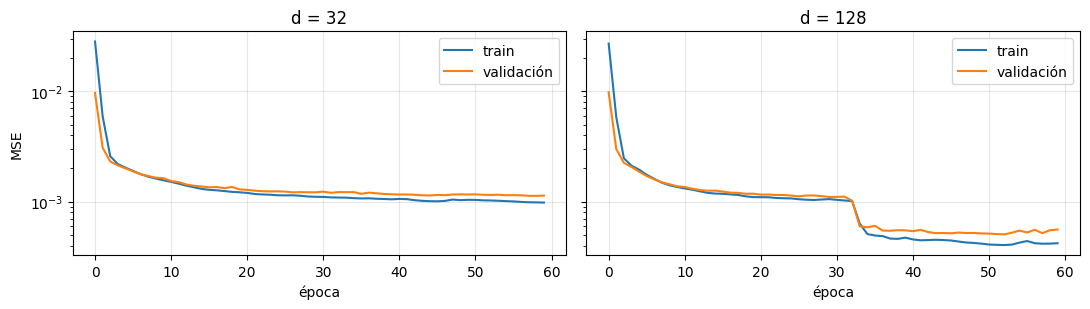

,params_total,best_epoch,train_time_s,infer_time_val_s,val_mse,val_ssim,val_gradient,val_score
latent_dim,,,,,,,,
32,725859,59,210,0.60,0.00113,0.9468,0.0037,0.0220
128,1610691,53,217,0.68,0.00051,0.9549,0.0035,0.0187


In [ ]:
# Curvas de aprendizaje (escala logarítmica en el eje Y)
fig, axes = plt.subplots(1, len(LATENT_DIMS), figsize=(11, 3.2), sharey=True)
for ax, d in zip(axes, LATENT_DIMS):
    h = results[d]["history"]
    ax.plot(h["loss"], label="train"); ax.plot(h["val_loss"], label="validación")
    ax.set_title(f"d = {d}"); ax.set_xlabel("época"); ax.set_yscale("log"); ax.grid(alpha=.3); ax.legend()
axes[0].set_ylabel("MSE")
plt.tight_layout(); plt.show()

# Tabla resumen de la comparación (también se guarda en CSV)
import pandas as pd
cols = ["latent_dim", "params_total", "best_epoch", "train_time_s", "infer_time_val_s",
        "val_mse", "val_ssim", "val_gradient", "val_score"]
table = pd.DataFrame([{c: results[d][c] for c in cols} for d in LATENT_DIMS]).set_index("latent_dim")
table.to_csv(os.path.join(RESULTS_DIR, "parte1_tabla.csv"))
table.style.format({"train_time_s": "{:.0f}", "infer_time_val_s": "{:.2f}", "val_mse": "{:.5f}",
                    "val_ssim": "{:.4f}", "val_gradient": "{:.4f}", "val_score": "{:.4f}"})

## 7. Reconstrucciones y mapas de error
Se usan las **512 imágenes de evaluación fijas** (las mismas para ambos modelos, y las que se usarán en la parte 2).

Primero se calculan las métricas sobre esas imágenes. Después se muestra una cuadrícula con:
- **Fila 1:** imagen original.
- **Filas 2 y 3:** reconstrucción con d = 32 y su **mapa de error** (error absoluto medio de los 3 canales en cada píxel; negro = sin error, amarillo = mucho error), con el MSE de esa imagen.
- **Filas 4 y 5:** lo mismo con d = 128.

El enunciado pide incluir **aciertos y fallos**, así que las imágenes se eligen ordenándolas por el error con d = 32: las 3 **mejores**, 2 de la **mediana** y las 3 **peores**.

**Qué se observa:**
- **Mejores casos:** rectas sin bordillos; MSE ≈ 0,0001 con ambos modelos. Casi indistinguibles del original.
- **Peores casos:** curvas con **bordillos rojo/blanco**. Ambos modelos los reconstruyen como una franja **rosa difusa**, es decir, el promedio de rojo y blanco. Es el efecto típico de entrenar con MSE: ante la duda, la red predice un valor intermedio que minimiza el error cuadrático. d = 128 lo hace algo mejor (MSE 0,0016–0,0022 frente a 0,0036–0,0039).
- **Indicador verde de dirección:** en las imágenes donde aparece, **d = 32 no lo reconstruye** (en el mapa de error aparece una mancha en la barra inferior) y **d = 128 sí**.
- **Textura de la hierba:** los cuadrados de verde más claro se convierten en manchas suaves y redondeadas en ambos modelos.
- La **forma de la pista y el coche** se conservan siempre bien.

d=32: métricas sobre imágenes de evaluación fijas → {'score': 0.02225, 'ssim': 0.94626, 'gradient': 0.00378, 'mse': 0.00114}
d=128: métricas sobre imágenes de evaluación fijas → {'score': 0.01912, 'ssim': 0.95398, 'gradient': 0.00355, 'mse': 0.00052}


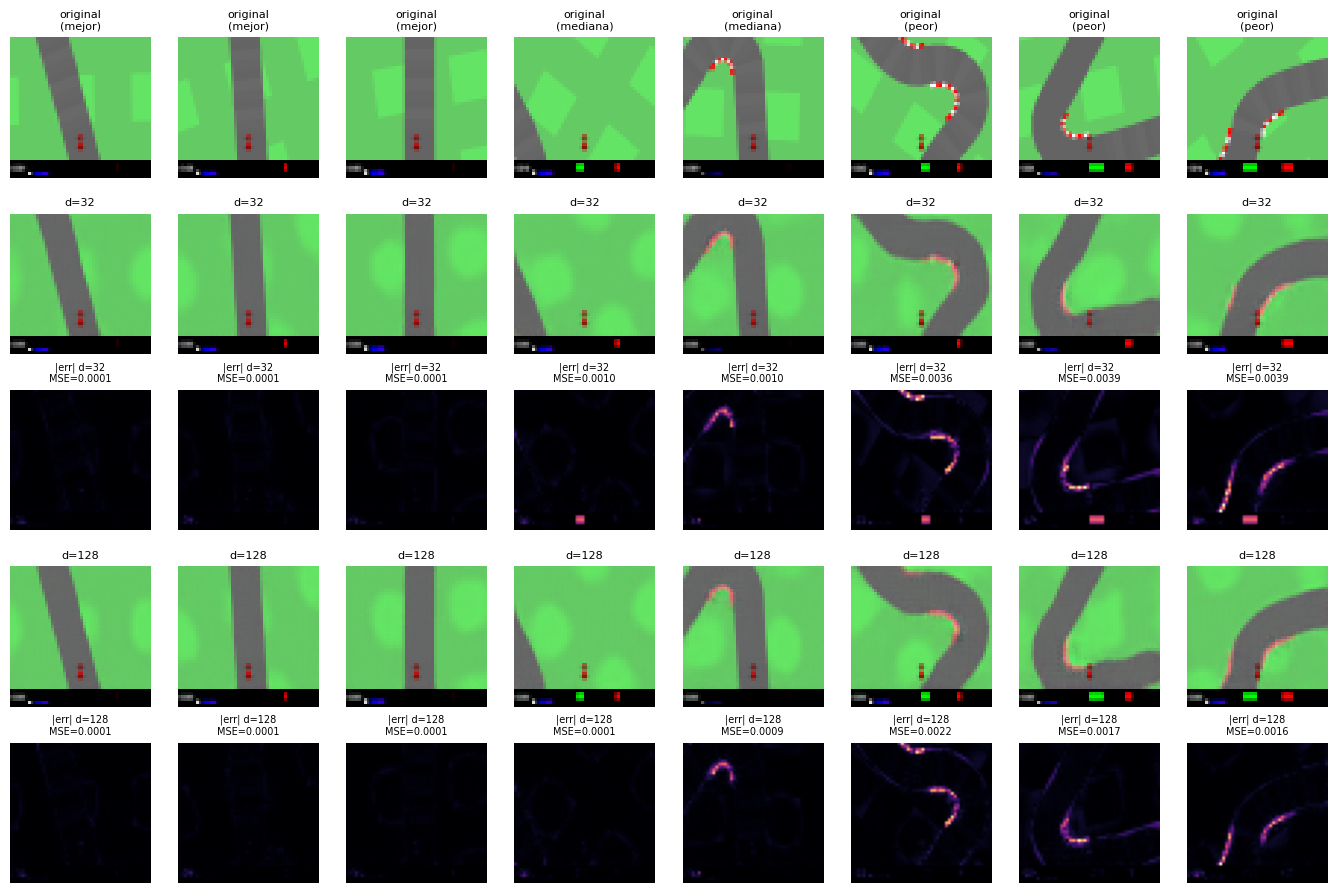

In [7]:
# Reconstrucciones de las imágenes de evaluación fijas con cada modelo (models[d][0] es el autoencoder)
recs = {d: np.clip(models[d][0].predict(X_eval, batch_size=512, verbose=0), 0, 1) for d in LATENT_DIMS}
for d in LATENT_DIMS:
    print(f"d={d}: métricas sobre imágenes de evaluación fijas →",
          {k: round(v, 5) for k, v in visual_metrics(X_eval, recs[d]).items()})

# Ordenamos las imágenes por su MSE con d=32 para mostrar aciertos y fallos
per_img = ((X_eval - recs[LATENT_DIMS[0]]) ** 2).mean(axis=(1, 2, 3))
order = np.argsort(per_img)                                   # de menor a mayor error
show = list(order[:3]) + list(order[len(order)//2:len(order)//2 + 2]) + list(order[-3:])
labels = ["mejor"] * 3 + ["mediana"] * 2 + ["peor"] * 3

# Cuadrícula: original + (reconstrucción, error) para cada d
rows = 1 + 2 * len(LATENT_DIMS)
fig, axes = plt.subplots(rows, len(show), figsize=(1.7 * len(show), 1.8 * rows))
for c, (k, lab) in enumerate(zip(show, labels)):
    axes[0, c].imshow(X_eval[k], interpolation="nearest"); axes[0, c].set_title(f"original\n({lab})", fontsize=8)
    for r, d in enumerate(LATENT_DIMS):
        err = np.abs(X_eval[k] - recs[d][k]).mean(-1)          # error absoluto medio sobre R, G y B
        axes[1 + 2*r, c].imshow(recs[d][k], interpolation="nearest")
        axes[1 + 2*r, c].set_title(f"d={d}", fontsize=8)
        axes[2 + 2*r, c].imshow(err, cmap="magma", vmin=0, vmax=0.5)   # misma escala en todos los mapas
        axes[2 + 2*r, c].set_title(f"|err| d={d}\nMSE={((X_eval[k]-recs[d][k])**2).mean():.4f}", fontsize=7)
for a in axes.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

### Mapa de error medio: dónde se pierde la información
Se promedia el error absoluto de cada píxel sobre las 512 imágenes de evaluación. El mapa resultante indica **en qué zonas de la imagen** falla sistemáticamente cada modelo. Los dos mapas usan la **misma escala de color** (0 a 0,1) para que se puedan comparar directamente: un mismo color significa el mismo error en ambos.

**Qué se observa:**
- El error se concentra en la **barra inferior de indicadores**. Son pocos píxeles, pero cambian mucho de una imagen a otra y son difíciles de codificar.
- Con d = 32 hay una zona muy caliente en el **centro de la barra (indicador verde de dirección)**; con d = 128 casi desaparece. Queda en ambos la zona de la izquierda (puntuación y velocidad).
- En el resto de la imagen el error es bajo y se reparte a lo largo de la pista, sobre todo en los bordes y la zona del coche.

Esto es relevante para las partes siguientes: los indicadores contienen información sobre la **velocidad y el giro** del coche, que el predictor necesitará para saber cómo se moverá la escena. Un autoencoder que los pierde le quita esa información al predictor, aunque en MSE la diferencia parezca pequeña.



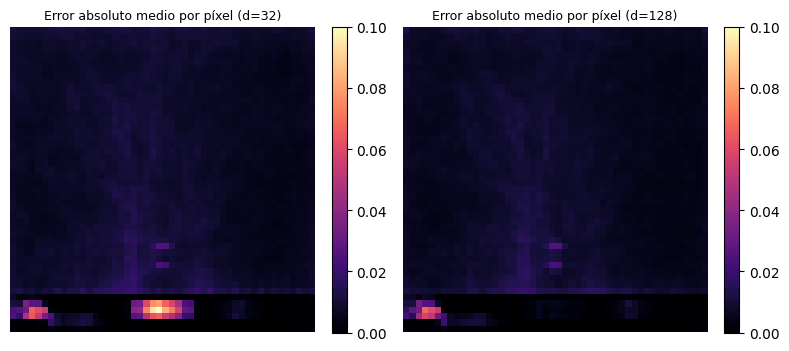

In [8]:
# Si la sesión es nueva (no hay reconstrucciones en memoria), las recalcula a partir de los modelos guardados
LATENT_DIMS = globals().get("LATENT_DIMS", [32, 128])
if "recs" not in globals():
    X_eval = np.load(os.path.join(DATA_DIR, "eval_images.npz"))["images"].astype("float32") / 255.0
    recs = {}
    for d in LATENT_DIMS:
        enc_l = keras.models.load_model(os.path.join(MODEL_DIR, f"encoder_d{d}.keras"))
        dec_l = keras.models.load_model(os.path.join(MODEL_DIR, f"decoder_d{d}.keras"))
        recs[d] = np.clip(dec_l.predict(enc_l.predict(X_eval, verbose=0), verbose=0), 0, 1)

# Mapa de error medio sobre todas las imágenes de evaluación: dónde se pierde la información
# vmin/vmax fijos: ambos mapas comparten la misma escala de color para poder compararlos
fig, axes = plt.subplots(1, len(LATENT_DIMS), figsize=(4 * len(LATENT_DIMS), 3.5))
for ax, d in zip(axes, LATENT_DIMS):
    im = ax.imshow(np.abs(X_eval - recs[d]).mean(axis=(0, -1)), cmap="magma", vmin=0, vmax=0.1)
    ax.set_title(f"Error absoluto medio por píxel (d={d})", fontsize=9); ax.axis("off")
    plt.colorbar(im, ax=ax, fraction=.046)
plt.tight_layout(); plt.show()

### Comprobación de los modelos guardados
Se comprueba que los ficheros `.keras` guardados funcionan **por separado**:
1. Se cargan `encoder_d{d}.keras` y `decoder_d{d}.keras` desde disco.
2. Se codifican 64 imágenes con el encoder → latentes de forma (64, d).
3. Se decodifican con el decoder → imágenes (64, 48, 48, 3).
4. Se verifica que el resultado coincide con el del autoencoder en memoria (tolerancia 10⁻⁴).



In [9]:
# Comprobación: los modelos guardados se cargan por separado y reproducen el resultado
for d in LATENT_DIMS:
    enc_l = keras.models.load_model(os.path.join(MODEL_DIR, f"encoder_d{d}.keras"))
    dec_l = keras.models.load_model(os.path.join(MODEL_DIR, f"decoder_d{d}.keras"))
    z = enc_l.predict(X_eval[:64], verbose=0)                # imágenes -> latentes (64, d)
    rec = dec_l.predict(z, verbose=0)                        # latentes -> imágenes (64, 48, 48, 3)
    assert z.shape == (64, d) and rec.shape == (64, 48, 48, 3)
    assert np.allclose(rec, recs[d][:64], atol=1e-4)         # igual que el autoencoder en memoria
    print(f"encoder_d{d}.keras + decoder_d{d}.keras ✔  latente {z.shape}")
print("Ficheros guardados:", sorted(os.listdir(MODEL_DIR)))

encoder_d32.keras + decoder_d32.keras ✔  latente (64, 32)


encoder_d128.keras + decoder_d128.keras ✔  latente (64, 128)
Ficheros guardados: ['ae_d128_best.weights.h5', 'ae_d32_best.weights.h5', 'decoder_d128.keras', 'decoder_d32.keras', 'encoder_d128.keras', 'encoder_d32.keras']


## 8. Conclusiones

### Resumen de resultados
| | Parámetros | Mejor época | Entrenamiento | Inferencia (3072 img) | MSE val | SSIM val | Score val |
|---|---|---|---|---|---|---|---|
| d = 32 | 725 859 | 59 | 210 s | 0,60 s | 0,00113 | 0,947 | 0,0220 |
| d = 128 | 1 610 691 | 53 | 217 s | 0,68 s | **0,00051** | **0,955** | **0,0187** |
| Referencia: repetir la última imagen (predicción a 24 pasos) | 0 | — | — | — | 0,0156 | 0,751 | 0,101 |

### Dimensiones y compresión
La imagen pasa por 48×48×3 = 6912 → 24×24×32 → 12×12×64 → 6×6×128 = 4608 → d. Es una compresión de **216×** con d = 32 y de **54×** con d = 128. La mayor parte del aumento de parámetros al pasar de d = 32 a d = 128 está en las dos capas densas (4608·d cada una): suponen el 41 % de los parámetros con d = 32 y el 74 % con d = 128.

### Comparación de tamaños latentes
Con 60 épocas, **d = 128 reduce el MSE a menos de la mitad** (0,00051 frente a 0,00113) y mejora el score (0,0187 frente a 0,0220), con 2,2× parámetros y un coste de tiempo casi igual (217 s frente a 210 s). Con 30 épocas la diferencia era mínima (0,00111 frente a 0,00118). La mejora llega de golpe hacia la época 32, cuando el modelo con d = 128 aprende a reconstruir el **indicador verde de dirección**. d = 32 no lo llegó a aprender con el mismo presupuesto y se estanca. d = 128 muestra un ligero sobreajuste a partir de la época 53; se usan los pesos de la mejor época. Hay que tener en cuenta que es **una sola semilla**: podemos decir que con el mismo presupuesto d = 128 aprendió el indicador y d = 32 no, pero no que d = 32 sea incapaz de aprenderlo.

### Información que se pierde
Ambos modelos conservan bien la **forma de la pista y la posición del coche**, y reconstruyen las rectas casi perfectamente (MSE ≈ 10⁻⁴). Pierden los **detalles de alta frecuencia**: los bordillos rojo/blanco salen como una franja rosa difusa y los cuadrados de hierba más clara se suavizan. Además, **d = 32 pierde el indicador de dirección** de la barra inferior. La pérdida MSE favorece reconstrucciones promediadas y penaliza poco los detalles pequeños, como los indicadores, aunque contengan información sobre la velocidad y el giro del coche relevante para predecir.

### Reconstruir frente a predecir
El autoencoder **reproduce la imagen que recibe**: toda la información necesaria está en su entrada. **Predecir** `x_{t+1}` es mucho más difícil: hay que modelar la dinámica del coche, el efecto de la acción y el tramo del circuito que todavía no se ha visto, que no está en la imagen actual. La referencia que repite la última imagen obtiene un score de 0,101 (0,060 en h = 1 y ≈ 0,107 en h = 24), mientras que la reconstrucción con d = 128 obtiene 0,019. Como el predictor de las partes 3–5 trabajará en este espacio latente y sus imágenes pasarán por el mismo decoder, **la calidad de reconstrucción es aproximadamente el límite inferior de error** que podrá alcanzar. El margen de mejora de los predictores estará entre esos dos valores.

### Tiempos
- Generación de datos: 945 s (entrenamiento) + 256 s (validación), en CPU.
- Entrenamiento (60 épocas, GPU T4): 210 s (d = 32) y 217 s (d = 128).
- Inferencia sobre las 3072 imágenes de validación: 0,60 s y 0,68 s.

### Elección para las partes siguientes
d = 128 es el mejor candidato: mejor reconstrucción en todas las métricas, conserva el indicador de dirección y su coste extra es pequeño. La elección definitiva se hará en la parte 2, al compararlo con el autoencoder residual.

## 9. Guía para la defensa
Preguntas que indica el enunciado y respuestas cortas:

**1. Dimensiones.** Entrada 48×48×3. Cada convolución con stride 2 divide el alto y el ancho entre 2 (48 → 24 → 12 → 6) y los filtros aumentan (32 → 64 → 128). 6·6·128 = 4608 valores, que una capa densa comprime a d. El decoder hace lo contrario: densa a 4608, reshape a 6×6×128 y tres `Conv2DTranspose` con stride 2 (6 → 12 → 24 → 48). Termina con una convolución de 3 filtros y sigmoide → 48×48×3 en [0, 1].

**2. Información perdida.** Detalles de alta frecuencia (bordillos rojo/blanco, textura de la hierba) y, con d = 32, el indicador de dirección. Se conserva la estructura: forma de la pista y posición del coche. El MSE produce imágenes "promedio" y borrosas.

**3. Reconstruir frente a predecir.** Reconstruir: la salida es la misma imagen de entrada; toda la información está disponible. Predecir: la salida es una imagen futura; hay que modelar la dinámica, la acción y el circuito no visto. Una buena reconstrucción no implica una buena predicción, pero sí limita la calidad máxima de la predicción en el espacio latente.

**Otras preguntas posibles:**
- *¿Por qué stride 2 y no max-pooling?* La red aprende cómo reducir la resolución en lugar de quedarse con el máximo fijo.
- *¿Por qué sigmoide al final?* Para que la salida esté en [0, 1], igual que las imágenes normalizadas.
- *¿Por qué el latente es lineal?* Para que pueda tomar cualquier valor real; en la parte 3 el predictor lo generará con una capa lineal.
- *¿Por qué separar por circuitos?* Para que la validación mida la generalización a circuitos nuevos y no haya fuga de información.
- *¿Por qué ModelCheckpoint?* Para quedarse con la mejor época en validación aunque luego haya sobreajuste.

**Cambios rápidos que pueden pedir:**
- *Cambiar el tamaño del latente:* modificar `LATENT_DIMS`.
- *Añadir o quitar filtros:* cambiar el primer argumento de las `Conv2D`; si cambian los filtros de `enc_conv3`, el `Flatten` ya no da 4608 y el decoder debe ajustar `Dense(6*6*filtros)` y el `Reshape`.
- *Añadir una reducción más (48 → 3):* añadir otra convolución con stride 2 en el encoder y otra `Conv2DTranspose` en el decoder, y ajustar `Reshape((3, 3, …))`.
- *Usar `UpSampling2D` en lugar de `Conv2DTranspose`:* `layers.UpSampling2D(2)` seguida de una `Conv2D`.

## 10. Declaración de ayuda externa e IA
_Adaptar a lo que se haya usado realmente:_

Se usó Claude (Anthropic) como asistente para generar la estructura inicial del código, explicar el enunciado y los ficheros proporcionados, y redactar un borrador de las explicaciones y conclusiones. El grupo revisó, ejecutó y validó el código; los resultados e interpretaciones se comprobaron sobre las salidas del notebook. Se usaron los ficheros proporcionados por el profesor (`dataset.py`, `carracing48.py`, `metric.py`) sin modificarlos.